<a href="https://colab.research.google.com/github/rssurekha8/ZeroTrace_DL/blob/main/ZeroTrace_Corrected_Full_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ZeroTrace — Corrected Deep Autoencoder for Network Intrusion Detection

This notebook uses NSL-KDD `KDDTrain+` and `KDDTest+`. The scaler is fitted **only on the normal training split**. The autoencoder and threshold are also learned only from normal records.

Run the cells from top to bottom in Google Colab. The model's final metrics must be regenerated by this corrected run; old metrics should not be reused automatically.

In [ ]:
# 1. Imports and reproducibility

import os
import random
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: []


In [ ]:
# 2. Download NSL-KDD files

train_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"
test_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"

train_file = "KDDTrain+.txt"
test_file = "KDDTest+.txt"

if not os.path.exists(train_file):
    result = tf.keras.utils.get_file(
        fname=train_file,
        origin=train_url,
        cache_dir=".",
        cache_subdir=""
    )
    if result != train_file and os.path.exists(result):
        os.replace(result, train_file)

if not os.path.exists(test_file):
    result = tf.keras.utils.get_file(
        fname=test_file,
        origin=test_url,
        cache_dir=".",
        cache_subdir=""
    )
    if result != test_file and os.path.exists(result):
        os.replace(result, test_file)

print("Dataset files ready.")

19109424/19109424 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
3441513/3441513 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset files ready.


In [ ]:
# 3. Load the dataset

columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised", "root_shell",
    "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "attack", "difficulty"
]

train_df = pd.read_csv(train_file, names=columns)
test_df = pd.read_csv(test_file, names=columns)

train_df["label"] = (train_df["attack"] != "normal").astype(int)
test_df["label"] = (test_df["attack"] != "normal").astype(int)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("\nTraining labels:")
print(train_df["label"].value_counts().sort_index().rename(index={0: "Normal", 1: "Attack"}))
print("\nTest labels:")
print(test_df["label"].value_counts().sort_index().rename(index={0: "Normal", 1: "Attack"}))

Training shape: (125973, 44)
Testing shape: (22544, 44)

Training labels:
label
Normal    67343
Attack    58630
Name: count, dtype: int64

Test labels:
label
Normal     9711
Attack    12833
Name: count, dtype: int64


In [ ]:
# 4. Identify attack types absent from KDDTrain+

train_attack_types = set(train_df.loc[train_df["attack"] != "normal", "attack"].unique())
test_attack_types = set(test_df.loc[test_df["attack"] != "normal", "attack"].unique())

unseen_attacks = sorted(test_attack_types - train_attack_types)
seen_test_attacks = sorted(test_attack_types & train_attack_types)

print("Attack types in KDDTrain+:", len(train_attack_types))
print("Attack types in KDDTest+:", len(test_attack_types))
print("\nAttack types present in both files:")
print(seen_test_attacks)
print("\nAttack types present in KDDTest+ but absent from KDDTrain+:")
print(unseen_attacks)

Attack types in KDDTrain+: 22
Attack types in KDDTest+: 37

Attack types present in both files:
['back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'imap', 'ipsweep', 'land', 'loadmodule', 'multihop', 'neptune', 'nmap', 'perl', 'phf', 'pod', 'portsweep', 'rootkit', 'satan', 'smurf', 'teardrop', 'warezmaster']

Attack types present in KDDTest+ but absent from KDDTrain+:
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


In [ ]:
# 5. Prepare features and align one-hot encoded columns

drop_columns = ["attack", "difficulty", "label"]

X_train_raw_df = train_df.drop(columns=drop_columns).copy()
X_test_raw_df = test_df.drop(columns=drop_columns).copy()

y_train = train_df["label"].to_numpy(dtype=np.int32)
y_test = test_df["label"].to_numpy(dtype=np.int32)

categorical_columns = ["protocol_type", "service", "flag"]

X_train_encoded_df = pd.get_dummies(
    X_train_raw_df,
    columns=categorical_columns,
    dtype=float
)

X_test_encoded_df = pd.get_dummies(
    X_test_raw_df,
    columns=categorical_columns,
    dtype=float
)

# Match test columns to the training feature schema.
X_test_encoded_df = X_test_encoded_df.reindex(
    columns=X_train_encoded_df.columns,
    fill_value=0
)

# Replace non-finite values and missing values.
X_train_encoded_df = X_train_encoded_df.replace([np.inf, -np.inf], np.nan).fillna(0)
X_test_encoded_df = X_test_encoded_df.replace([np.inf, -np.inf], np.nan).fillna(0)

feature_columns = list(X_train_encoded_df.columns)

X_train_all = X_train_encoded_df.to_numpy(dtype=np.float32)
X_test_all = X_test_encoded_df.to_numpy(dtype=np.float32)

print("Encoded training features:", X_train_all.shape)
print("Encoded testing features:", X_test_all.shape)
print("NaN values in train:", np.isnan(X_train_all).sum())
print("NaN values in test:", np.isnan(X_test_all).sum())

Encoded training features: (125973, 122)
Encoded testing features: (22544, 122)
NaN values in train: 0
NaN values in test: 0


In [ ]:
# 6. Split normal records first, then fit scaler on normal training data only

normal_mask = (y_train == 0)
X_normal_raw = X_train_all[normal_mask]

X_normal_train_raw, X_normal_val_raw = train_test_split(
    X_normal_raw,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

scaler = StandardScaler()

# IMPORTANT: scaler statistics are learned only from normal training records.
X_normal_train = scaler.fit_transform(X_normal_train_raw).astype(np.float32)
X_normal_val = scaler.transform(X_normal_val_raw).astype(np.float32)
X_test_scaled = scaler.transform(X_test_all).astype(np.float32)

print("Normal records available:", len(X_normal_raw))
print("Normal training shape:", X_normal_train.shape)
print("Normal validation shape:", X_normal_val.shape)
print("Scaled test shape:", X_test_scaled.shape)

Normal records available: 67343
Normal training shape: (53874, 122)
Normal validation shape: (13469, 122)
Scaled test shape: (22544, 122)


In [ ]:
# 7. Build the deep autoencoder

input_dim = X_normal_train.shape[1]

input_layer = Input(shape=(input_dim,), name="input_features")
x = Dense(128, activation="relu", name="encoder_128")(input_layer)
x = Dropout(0.2, name="dropout")(x)
x = Dense(64, activation="relu", name="encoder_64")(x)
latent = Dense(32, activation="relu", name="latent_space")(x)
x = Dense(64, activation="relu", name="decoder_64")(latent)
x = Dense(128, activation="relu", name="decoder_128")(x)
output_layer = Dense(input_dim, activation="linear", name="reconstructed_features")(x)

autoencoder = Model(inputs=input_layer, outputs=output_layer, name="ZeroTrace_Autoencoder")
autoencoder.compile(optimizer="adam", loss="mse")

autoencoder.summary()

Model: "ZeroTrace_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_features (InputLayer)     │ (None, 122)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_128 (Dense)             │ (None, 128)            │        15,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_64 (Dense)              │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_64 (Dense)              │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_128 (Dense)             │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_features (Dense)  │ (None, 122)            │        15,738 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,250 (204.10 KB)

 Trainable params: 52,250 (204.10 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 8. Train only on normal records

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_normal_train,
    X_normal_train,
    validation_data=(X_normal_val, X_normal_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

print("Training completed.")

Epoch 1/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3930 - val_loss: 0.4230
Epoch 2/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2276 - val_loss: 0.3472
Epoch 3/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.1775 - val_loss: 0.2978
Epoch 4/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1495 - val_loss: 0.2707
Epoch 5/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1294 - val_loss: 0.2502
Epoch 6/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.1134 - val_loss: 0.2257
Epoch 7/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1027 - val_loss: 0.2211
Epoch 8/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0893 - val_loss: 0.1962
Epoch 9/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0833 - val_loss: 0.1927
Epoch 10/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0778 - val_loss: 0.1929
Epoch 11/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0772 - val_loss: 0.1964
Epoch 12/100
211/211 ━━━━━━━━━━━━━━━━━

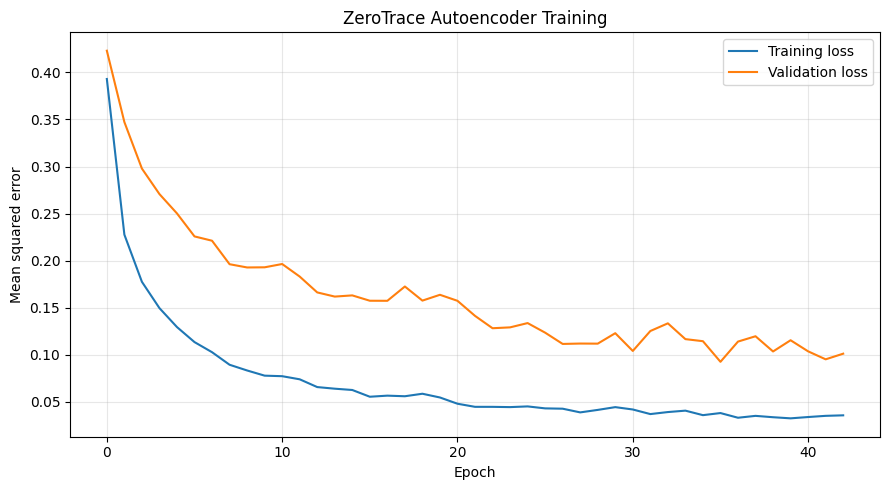

In [ ]:
# 9. Plot training and validation loss

plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("ZeroTrace Autoencoder Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 10. Compute reconstruction errors and set threshold from normal validation data

val_reconstructed = autoencoder.predict(X_normal_val, batch_size=1024, verbose=0)
val_errors = np.mean(np.square(X_normal_val - val_reconstructed), axis=1)

test_reconstructed = autoencoder.predict(X_test_scaled, batch_size=1024, verbose=0)
test_errors = np.mean(np.square(X_test_scaled - test_reconstructed), axis=1)

THRESHOLD_PERCENTILE = 95
threshold = float(np.percentile(val_errors, THRESHOLD_PERCENTILE))

# Score above threshold means intrusion.
y_pred = (test_errors > threshold).astype(np.int32)

print(f"Threshold percentile: {THRESHOLD_PERCENTILE}")
print(f"Reconstruction-error threshold: {threshold:.8f}")
print(f"Mean normal-validation error: {val_errors.mean():.8f}")
print(f"Mean test error: {test_errors.mean():.8f}")

Threshold percentile: 95
Reconstruction-error threshold: 0.06922741
Mean normal-validation error: 0.09247497
Mean test error: 0.75727397


In [ ]:
# 11. Evaluate overall test performance

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, test_errors)
pr_auc = average_precision_score(y_test, test_errors)

fpr = fp / (fp + tn) if (fp + tn) else 0.0
fnr = fn / (fn + tp) if (fn + tp) else 0.0

# Correct overall intrusion detection rate (same as positive-class recall).
detection_rate = tp / (tp + fn) if (tp + fn) else 0.0

print("Confusion matrix counts:")
print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)
print()
print(f"Accuracy:          {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision:         {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:            {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-score:          {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC:           {roc_auc:.4f}")
print(f"PR-AUC:            {pr_auc:.4f}")
print(f"False positive rate: {fpr:.4f} ({fpr*100:.2f}%)")
print(f"False negative rate: {fnr:.4f} ({fnr*100:.2f}%)")
print(f"Detection rate:    {detection_rate:.4f} ({detection_rate*100:.2f}%)")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Intrusion"],
    zero_division=0
))

Confusion matrix counts:
TN: 8760 FP: 951 FN: 1844 TP: 10989

Accuracy:          0.8760 (87.60%)
Precision:         0.9204 (92.04%)
Recall:            0.8563 (85.63%)
F1-score:          0.8872 (88.72%)
ROC-AUC:           0.9486
PR-AUC:            0.9493
False positive rate: 0.0979 (9.79%)
False negative rate: 0.1437 (14.37%)
Detection rate:    0.8563 (85.63%)

Classification report:
              precision    recall  f1-score   support

      Normal       0.83      0.90      0.86      9711
   Intrusion       0.92      0.86      0.89     12833

    accuracy                           0.88     22544
   macro avg       0.87      0.88      0.87     22544
weighted avg       0.88      0.88      0.88     22544



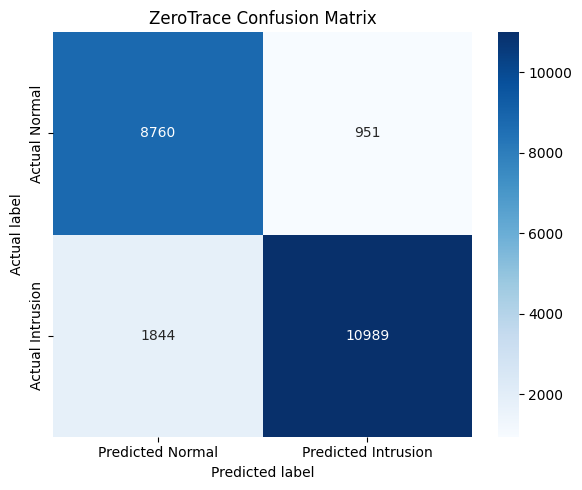

In [ ]:
# 12. Plot confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Normal", "Predicted Intrusion"],
    yticklabels=["Actual Normal", "Actual Intrusion"]
)
plt.title("ZeroTrace Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

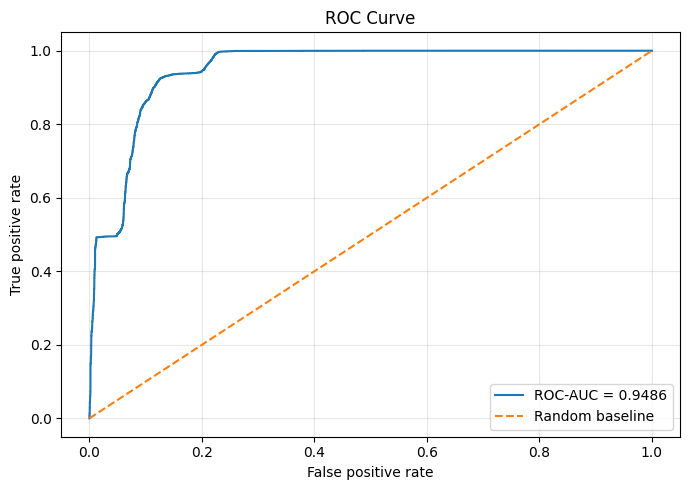

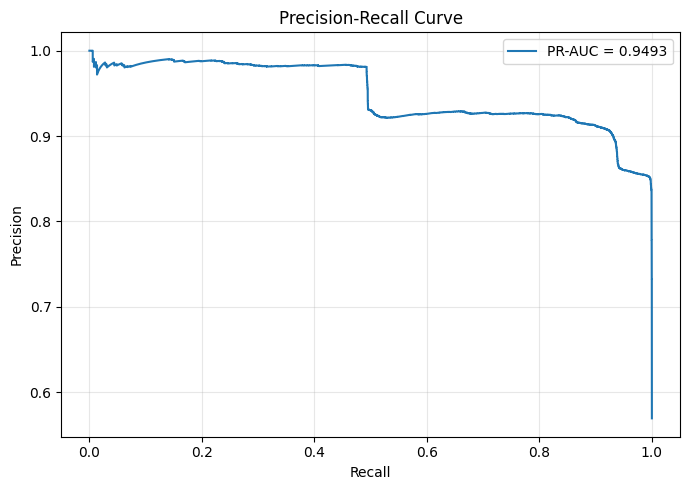

In [ ]:
# 13. Plot ROC and Precision-Recall curves

fpr_curve, tpr_curve, _ = roc_curve(y_test, test_errors)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_errors)

plt.figure(figsize=(7, 5))
plt.plot(fpr_curve, tpr_curve, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 14. Detection rate for every attack type in KDDTest+

attack_results = []

for attack_name in sorted(test_df["attack"].unique()):
    mask = (test_df["attack"].to_numpy() == attack_name)
    total = int(mask.sum())
    detected = int(np.sum(y_pred[mask] == 1))
    missed = total - detected
    attack_detection_rate = detected / total if total else 0.0
    mean_error = float(np.mean(test_errors[mask])) if total else 0.0

    attack_results.append({
        "Attack Type": attack_name,
        "Is Intrusion": attack_name != "normal",
        "Total Samples": total,
        "Detected as Intrusion": detected,
        "Missed": missed,
        "Detection Rate": attack_detection_rate,
        "Detection Rate (%)": attack_detection_rate * 100,
        "Mean Reconstruction Error": mean_error
    })

attack_results_df = pd.DataFrame(attack_results)
display(attack_results_df.sort_values("Detection Rate"))

,Attack Type,Is Intrusion,Total Samples,Detected as Intrusion,Missed,Detection Rate,Detection Rate (%),Mean Reconstruction Error
34,worm,True,2,0,2,0.000000,0.000000,0.013646
28,snmpgetattack,True,178,2,176,0.011236,1.123596,0.011838
29,snmpguess,True,331,5,326,0.015106,1.510574,0.012404
16,normal,False,9711,951,8760,0.097930,9.793018,0.061309
1,back,True,359,65,294,0.181058,18.105850,0.081619
10,mailbomb,True,293,75,218,0.255973,25.597270,0.048196
33,warezmaster,True,944,243,701,0.257415,25.741525,0.118599
23,rootkit,True,13,7,6,0.538462,53.846154,3.970453
26,sendmail,True,14,8,6,0.571429,57.142857,0.362391
3,ftp_write,True,3,2,1,0.666667,66.666667,0.987823


In [ ]:
# 15. Evaluate attack types absent from KDDTrain+

unseen_mask = test_df["attack"].isin(unseen_attacks).to_numpy()
unseen_true = y_test[unseen_mask]
unseen_pred = y_pred[unseen_mask]
unseen_errors = test_errors[unseen_mask]

unseen_total = int(unseen_mask.sum())
unseen_detected = int(np.sum(unseen_pred == 1))
unseen_missed = unseen_total - unseen_detected

unseen_detection_rate = (
    unseen_detected / unseen_total if unseen_total else 0.0
)

print("True unseen attack types:")
print(unseen_attacks)
print("Total records from unseen attack types:", unseen_total)
print("Detected:", unseen_detected)
print("Missed:", unseen_missed)
print(
    f"Unseen-attack detection rate: {unseen_detection_rate:.4f} "
    f"({unseen_detection_rate*100:.2f}%)"
)

unseen_results = []

for attack_name in unseen_attacks:
    mask = (test_df["attack"].to_numpy() == attack_name)
    total = int(mask.sum())
    detected = int(np.sum(y_pred[mask] == 1))
    missed = total - detected
    attack_detection_rate = detected / total if total else 0.0
    mean_error = float(np.mean(test_errors[mask])) if total else 0.0

    unseen_results.append({
        "Attack Type": attack_name,
        "Total Samples": total,
        "Detected": detected,
        "Missed": missed,
        "Detection Rate": attack_detection_rate,
        "Detection Rate (%)": attack_detection_rate * 100,
        "Mean Reconstruction Error": mean_error
    })

unseen_results_df = pd.DataFrame(unseen_results)
display(unseen_results_df)

True unseen attack types:
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Total records from unseen attack types: 3750
Detected: 3006
Missed: 744
Unseen-attack detection rate: 0.8016 (80.16%)


,Attack Type,Total Samples,Detected,Missed,Detection Rate,Detection Rate (%),Mean Reconstruction Error
0,apache2,737,735,2,0.997286,99.728630,0.527142
1,httptunnel,133,132,1,0.992481,99.248120,0.461529
2,mailbomb,293,75,218,0.255973,25.597270,0.048196
3,mscan,996,996,0,1.000000,100.000000,2.352446
4,named,17,14,3,0.823529,82.352941,3.199378
5,processtable,685,685,0,1.000000,100.000000,0.776119
6,ps,15,10,5,0.666667,66.666667,1.836853
7,saint,319,318,1,0.996865,99.686520,0.865357
8,sendmail,14,8,6,0.571429,57.142857,0.362391
9,snmpgetattack,178,2,176,0.011236,1.123596,0.011838


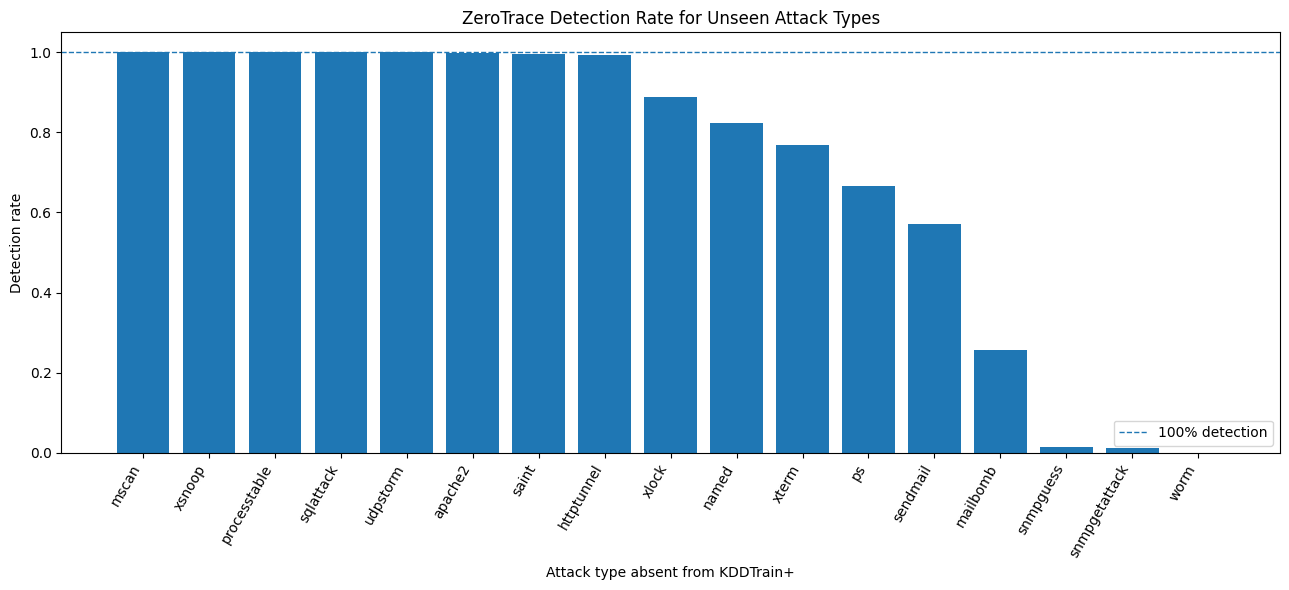

In [ ]:
# 16. Plot unseen-attack detection rates

if not unseen_results_df.empty:
    plot_df = unseen_results_df.sort_values("Detection Rate", ascending=False)

    plt.figure(figsize=(13, 6))
    plt.bar(plot_df["Attack Type"], plot_df["Detection Rate"])
    plt.axhline(1.0, linestyle="--", linewidth=1, label="100% detection")
    plt.xticks(rotation=60, ha="right")
    plt.xlabel("Attack type absent from KDDTrain+")
    plt.ylabel("Detection rate")
    plt.title("ZeroTrace Detection Rate for Unseen Attack Types")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.tight_layout()
    plt.show()

,Percentile,Threshold,Accuracy,Precision,Recall,F1
0,90,0.033138,0.895360,0.910874,0.904699,0.907776
1,92,0.042781,0.886178,0.914159,0.882958,0.898288
2,95,0.069227,0.876020,0.920352,0.856308,0.887176
3,97,0.118672,0.853531,0.925149,0.808073,0.862657
4,99,0.326554,0.755412,0.927262,0.618873,0.742312


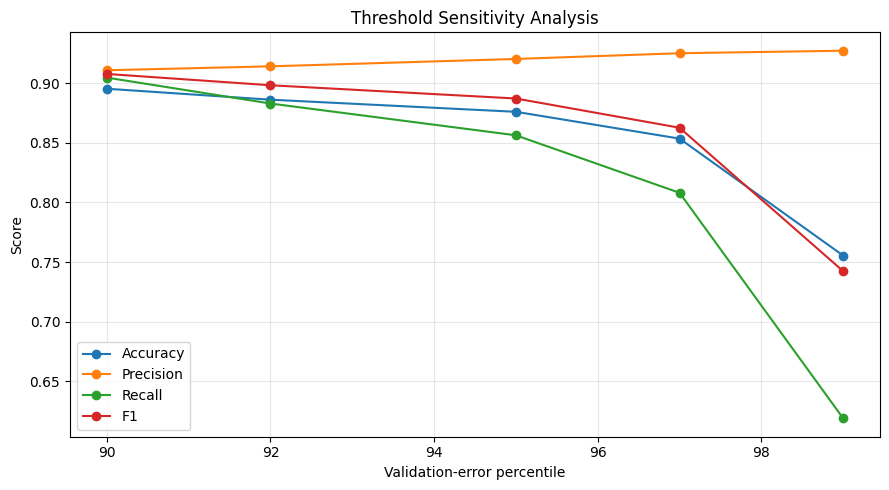

In [ ]:
# 17. Threshold sensitivity analysis
# These values are for analysis only. Keep the preselected 95th percentile
# as the primary result unless the threshold-selection protocol is changed
# before evaluating the test set.

percentiles = [90, 92, 95, 97, 99]
sensitivity_results = []

for percentile in percentiles:
    current_threshold = float(np.percentile(val_errors, percentile))
    current_pred = (test_errors > current_threshold).astype(np.int32)

    sensitivity_results.append({
        "Percentile": percentile,
        "Threshold": current_threshold,
        "Accuracy": accuracy_score(y_test, current_pred),
        "Precision": precision_score(y_test, current_pred, zero_division=0),
        "Recall": recall_score(y_test, current_pred, zero_division=0),
        "F1": f1_score(y_test, current_pred, zero_division=0)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)
display(sensitivity_df)

plt.figure(figsize=(9, 5))
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    plt.plot(
        sensitivity_df["Percentile"],
        sensitivity_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Validation-error percentile")
plt.ylabel("Score")
plt.title("Threshold Sensitivity Analysis")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 18. Create final metrics table

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC",
        "False Positive Rate",
        "False Negative Rate",
        "Overall Intrusion Detection Rate",
        "True Unseen Attack Detection Rate",
        "Threshold",
        "Threshold Percentile"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        fpr,
        fnr,
        detection_rate,
        unseen_detection_rate,
        threshold,
        THRESHOLD_PERCENTILE
    ]
})

final_results["Percentage"] = np.where(
    final_results["Metric"].isin([
        "Accuracy", "Precision", "Recall", "F1 Score",
        "False Positive Rate", "False Negative Rate",
        "Overall Intrusion Detection Rate",
        "True Unseen Attack Detection Rate"
    ]),
    final_results["Value"] * 100,
    np.nan
)

display(final_results)

print("=" * 55)
print("ZEROTRACE CORRECTED FINAL RESULTS")
print("=" * 55)
for _, row in final_results.iterrows():
    if pd.notna(row["Percentage"]):
        print(f'{row["Metric"]:<40}: {row["Value"]:.4f} ({row["Percentage"]:.2f}%)')
    else:
        print(f'{row["Metric"]:<40}: {row["Value"]}')
print("=" * 55)

,Metric,Value,Percentage
0,Accuracy,0.876020,87.602023
1,Precision,0.920352,92.035176
2,Recall,0.856308,85.630796
3,F1 Score,0.887176,88.717555
4,ROC-AUC,0.948562,NaN
5,PR-AUC,0.949294,NaN
6,False Positive Rate,0.097930,9.793018
7,False Negative Rate,0.143692,14.369204
8,Overall Intrusion Detection Rate,0.856308,85.630796
9,True Unseen Attack Detection Rate,0.801600,80.160000


ZEROTRACE CORRECTED FINAL RESULTS
Accuracy                                : 0.8760 (87.60%)
Precision                               : 0.9204 (92.04%)
Recall                                  : 0.8563 (85.63%)
F1 Score                                : 0.8872 (88.72%)
ROC-AUC                                 : 0.9485620523682223
PR-AUC                                  : 0.9492935318331286
False Positive Rate                     : 0.0979 (9.79%)
False Negative Rate                     : 0.1437 (14.37%)
Overall Intrusion Detection Rate        : 0.8563 (85.63%)
True Unseen Attack Detection Rate       : 0.8016 (80.16%)
Threshold                               : 0.06922741234302521
Threshold Percentile                    : 95.0


In [ ]:
# 19. Export results and model artifacts

results_df = pd.DataFrame({
    "Actual Label": y_test,
    "Predicted Label": y_pred,
    "Reconstruction Error": test_errors,
    "Actual Attack Type": test_df["attack"].to_numpy(),
    "Is Unseen Attack Type": test_df["attack"].isin(unseen_attacks).to_numpy()
})

results_df.to_csv("ZeroTrace_Test_Results.csv", index=False)
attack_results_df.to_csv("ZeroTrace_Attack_Results.csv", index=False)
unseen_results_df.to_csv("ZeroTrace_True_Unseen_Attacks.csv", index=False)
sensitivity_df.to_csv("ZeroTrace_Threshold_Sensitivity.csv", index=False)
final_results.to_csv("ZeroTrace_Final_Results.csv", index=False)

with pd.ExcelWriter("ZeroTrace_Final_Results.xlsx") as writer:
    final_results.to_excel(writer, sheet_name="Final Results", index=False)
    attack_results_df.to_excel(writer, sheet_name="Attack Analysis", index=False)
    unseen_results_df.to_excel(writer, sheet_name="True Unseen Attacks", index=False)
    sensitivity_df.to_excel(writer, sheet_name="Threshold Sensitivity", index=False)
    results_df.to_excel(writer, sheet_name="Per-record Results", index=False)

autoencoder.save("ZeroTrace_Deep_Autoencoder.keras")

with open("ZeroTrace_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("ZeroTrace_feature_columns.pkl", "wb") as f:
    pickle.dump(feature_columns, f)

with open("ZeroTrace_threshold.pkl", "wb") as f:
    pickle.dump({
        "threshold": threshold,
        "threshold_percentile": THRESHOLD_PERCENTILE,
        "seed": SEED
    }, f)

print("Saved model, scaler, feature columns, threshold, CSV files, and Excel workbook.")

Saved model, scaler, feature columns, threshold, CSV files, and Excel workbook.
